# Mental Health Dataset — Data Cleaning, Feature Engineering, and Clustering

Python/Jupyter conversion of the supplied R workflow. This notebook covers:
1. Loading and inspecting the dataset
2. Missing-value analysis and categorical standardization
3. Timestamp parsing and temporal features
4. Composite risk, support, isolation, and work-life indicators
5. Cardinality optimization and a stratified train/test split
6. K-means clustering, cluster interpretation, and silhouette validation
7. Assigning a cluster/risk label to a new example

**Important:** This is an analytical workflow, not a clinical diagnostic tool. The composite score and labels reproduce the rules in the supplied R script; they are not validated medical measures.

## 1. Environment and imports

Install dependencies in a terminal or in a notebook cell if needed:

```bash
python -m pip install --upgrade pip
python -m pip install pandas numpy matplotlib seaborn scikit-learn openpyxl jupyter ipykernel
```

Then start Jupyter with `jupyter lab` or `jupyter notebook`. If you're using Google Colab, most libraries are already installed; upload the CSV when prompted.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_samples, silhouette_score
from sklearn.decomposition import PCA

RANDOM_STATE = 123
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)
sns.set_theme(style="whitegrid")

print("Python environment ready.")

Python environment ready.


## 2. Load the dataset

Put `Mental_Health_Dataset.csv` in the same folder as this notebook, or change `DATA_PATH` below. The sample shown in the request contains tab-separated columns; the actual dataset is commonly a CSV. The loader detects the separator when possible.

In [2]:
DATA_PATH = Path("Mental_Health_Dataset.csv")

if not DATA_PATH.exists():
    # In Google Colab, uncomment the following lines to upload the CSV:
    # from google.colab import files
    # uploaded = files.upload()
    # DATA_PATH = Path(next(iter(uploaded)))
    raise FileNotFoundError(
        f"Dataset not found at: {DATA_PATH.resolve()}\n"
        "Place Mental_Health_Dataset.csv beside this notebook or update DATA_PATH."
    )

mental_health = pd.read_csv(DATA_PATH, sep=None, engine="python")
mental_health.columns = mental_health.columns.str.strip()
print(f"Loaded: {DATA_PATH.resolve()}")
display(mental_health.head())

Loaded: C:\Users\athar\Desktop\VITC\Sem 7\Healthcare Data Analytics\Project\DA\Finalize\Mental_Health_Dataset.csv


,Timestamp,Gender,Country,Occupation,self_employed,family_history,treatment,Days_Indoors,Growing_Stress,Changes_Habits,Mental_Health_History,Mood_Swings,Coping_Struggles,Work_Interest,Social_Weakness,mental_health_interview,care_options
0,8/27/2014 11:29,Female,United States,Corporate,NaN,No,Yes,1-14 days,Yes,No,Yes,Medium,No,No,Yes,No,Not sure
1,8/27/2014 11:31,Female,United States,Corporate,NaN,Yes,Yes,1-14 days,Yes,No,Yes,Medium,No,No,Yes,No,No
2,8/27/2014 11:32,Female,United States,Corporate,NaN,Yes,Yes,1-14 days,Yes,No,Yes,Medium,No,No,Yes,No,Yes
3,8/27/2014 11:37,Female,United States,Corporate,No,Yes,Yes,1-14 days,Yes,No,Yes,Medium,No,No,Yes,Maybe,Yes
4,8/27/2014 11:43,Female,United States,Corporate,No,Yes,Yes,1-14 days,Yes,No,Yes,Medium,No,No,Yes,No,Yes


## 3. Initial inspection

In [3]:
print("Dimensions:", mental_health.shape)
print("Number of rows:", len(mental_health))
print("Number of columns:", mental_health.shape[1])
print("\nColumn names:")
print(mental_health.columns.tolist())

print("\nDataFrame info:")
mental_health.info()

print("\nStatistical summary:")
display(mental_health.describe(include="all").T)

unique_summary = (
    mental_health.nunique(dropna=False)
    .rename("Unique_Values")
    .rename_axis("Column")
    .reset_index()
    .sort_values("Unique_Values", ascending=False)
)
display(unique_summary)

Dimensions: (292364, 17)
Number of rows: 292364
Number of columns: 17

Column names:
['Timestamp', 'Gender', 'Country', 'Occupation', 'self_employed', 'family_history', 'treatment', 'Days_Indoors', 'Growing_Stress', 'Changes_Habits', 'Mental_Health_History', 'Mood_Swings', 'Coping_Struggles', 'Work_Interest', 'Social_Weakness', 'mental_health_interview', 'care_options']

DataFrame info:
<class 'pandas.DataFrame'>
RangeIndex: 292364 entries, 0 to 292363
Data columns (total 17 columns):
 #   Column                   Non-Null Count   Dtype
---  ------                   --------------   -----
 0   Timestamp                292364 non-null  str  
 1   Gender                   292364 non-null  str  
 2   Country                  292364 non-null  str  
 3   Occupation               292364 non-null  str  
 4   self_employed            287162 non-null  str  
 5   family_history           292364 non-null  str  
 6   treatment                292364 non-null  str  
 7   Days_Indoors             292

,count,unique,top,freq
Timestamp,292364,580,8/27/2014 11:43,2384
Gender,292364,2,Male,239850
Country,292364,35,United States,171308
Occupation,292364,5,Housewife,66351
self_employed,287162,2,No,257994
family_history,292364,2,No,176832
treatment,292364,2,Yes,147606
Days_Indoors,292364,5,1-14 days,63548
Growing_Stress,292364,3,Maybe,99985
Changes_Habits,292364,3,Yes,109523


,Column,Unique_Values
0,Timestamp,580
2,Country,35
3,Occupation,5
7,Days_Indoors,5
4,self_employed,3
8,Growing_Stress,3
11,Mood_Swings,3
10,Mental_Health_History,3
9,Changes_Habits,3
15,mental_health_interview,3


## 4. Missing-value analysis and initial treatment

In [4]:
# Treat blank strings and whitespace-only strings as missing.
mental_health = mental_health.replace(r"^\s*$", np.nan, regex=True)

missing_summary = pd.DataFrame({
    "Missing_Count": mental_health.isna().sum(),
    "Total_Rows": len(mental_health),
})
missing_summary["Missing_Percentage"] = (
    (missing_summary["Missing_Count"] / max(len(mental_health), 1)) * 100
).round(2)
missing_summary = missing_summary.sort_values("Missing_Percentage", ascending=False)
display(missing_summary)

# Match the original R intent: explicitly mark missing values in these fields as Unknown.
for col in ["self_employed", "mental_health_interview"]:
    if col in mental_health.columns:
        mental_health[col] = mental_health[col].fillna("Unknown")

print("Missing values after initial treatment:")
display(mental_health.isna().sum().rename("Missing_Count").to_frame())

,Missing_Count,Total_Rows,Missing_Percentage
self_employed,5202,292364,1.78
Timestamp,0,292364,0.00
Gender,0,292364,0.00
Country,0,292364,0.00
Occupation,0,292364,0.00
family_history,0,292364,0.00
treatment,0,292364,0.00
Days_Indoors,0,292364,0.00
Growing_Stress,0,292364,0.00
Changes_Habits,0,292364,0.00


Missing values after initial treatment:


,Missing_Count
Timestamp,0
Gender,0
Country,0
Occupation,0
self_employed,0
family_history,0
treatment,0
Days_Indoors,0
Growing_Stress,0
Changes_Habits,0


## 5. Parse timestamps and set categorical columns

In [5]:
if "Timestamp" not in mental_health.columns:
    raise KeyError("Expected a 'Timestamp' column in the dataset.")

# Handles timestamps such as 8/27/2014 11:29.
mental_health["Timestamp"] = pd.to_datetime(
    mental_health["Timestamp"], errors="coerce", format="mixed"
)
print("Timestamp dtype:", mental_health["Timestamp"].dtype)
display(mental_health[["Timestamp"]].head())

categorical_columns = [
    "Gender", "Country", "Occupation", "self_employed", "family_history",
    "treatment", "Days_Indoors", "Growing_Stress", "Changes_Habits",
    "Mental_Health_History", "Mood_Swings", "Coping_Struggles",
    "Work_Interest", "Social_Weakness", "mental_health_interview", "care_options"
]
categorical_columns = [c for c in categorical_columns if c in mental_health.columns]
for col in categorical_columns:
    mental_health[col] = mental_health[col].astype("category")

print("Categorical levels:")
for col in categorical_columns:
    print(f"\n{col}: {list(mental_health[col].cat.categories)}")

Timestamp dtype: datetime64[us]


,Timestamp
0,2014-08-27 11:29:00
1,2014-08-27 11:31:00
2,2014-08-27 11:32:00
3,2014-08-27 11:37:00
4,2014-08-27 11:43:00


Categorical levels:

Gender: ['Female', 'Male']

Country: ['Australia', 'Belgium', 'Bosnia and Herzegovina', 'Brazil', 'Canada', 'Colombia', 'Costa Rica', 'Croatia', 'Czech Republic', 'Denmark', 'Finland', 'France', 'Georgia', 'Germany', 'Greece', 'India', 'Ireland', 'Israel', 'Italy', 'Mexico', 'Moldova', 'Netherlands', 'New Zealand', 'Nigeria', 'Philippines', 'Poland', 'Portugal', 'Russia', 'Singapore', 'South Africa', 'Sweden', 'Switzerland', 'Thailand', 'United Kingdom', 'United States']

Occupation: ['Business', 'Corporate', 'Housewife', 'Others', 'Student']

self_employed: ['No', 'Unknown', 'Yes']

family_history: ['No', 'Yes']

treatment: ['No', 'Yes']

Days_Indoors: ['1-14 days', '15-30 days', '31-60 days', 'Go out Every day', 'More than 2 months']

Growing_Stress: ['Maybe', 'No', 'Yes']

Changes_Habits: ['Maybe', 'No', 'Yes']

Mental_Health_History: ['Maybe', 'No', 'Yes']

Mood_Swings: ['High', 'Low', 'Medium']

Coping_Struggles: ['No', 'Yes']

Work_Interest: ['Maybe', 'No', '

## 6. Check and standardize inconsistent category values

In [6]:
def show_value_counts(data, column_name):
    print(f"\n{column_name}:")
    display(data[column_name].astype("string").value_counts(dropna=False).to_frame("Count"))

for col in ["care_options", "mental_health_interview", "family_history", "treatment"]:
    if col in mental_health.columns:
        show_value_counts(mental_health, col)

def normalize_yes_no_unknown(series):
    values = series.astype("string").str.strip()
    lowered = values.str.lower()
    result = values.copy()
    result[lowered.isin(["yes", "y"])] = "Yes"
    result[lowered.isin(["no", "n"])] = "No"
    result[values.isna()] = "Unknown"
    return result

if "care_options" in mental_health.columns:
    values = mental_health["care_options"].astype("string").str.strip()
    lowered = values.str.lower()
    normalized = values.copy()
    normalized[lowered.isin(["yes", "y"])] = "Yes"
    normalized[lowered.isin(["no", "n"])] = "No"
    normalized[lowered.isin(["not sure", "notsure", "maybe"])] = "Not sure"
    normalized[values.isna()] = "Unknown"
    mental_health["care_options"] = normalized.astype("category")

if "mental_health_interview" in mental_health.columns:
    values = mental_health["mental_health_interview"].astype("string").str.strip()
    lowered = values.str.lower()
    normalized = values.copy()
    normalized[lowered.isin(["yes", "y"])] = "Yes"
    normalized[lowered.isin(["no", "n"])] = "No"
    normalized[lowered.isin(["maybe", "not sure"])] = "Maybe"
    normalized[values.isna()] = "Unknown"
    mental_health["mental_health_interview"] = normalized.astype("category")

yes_no_columns = [
    "family_history", "treatment", "Growing_Stress", "Changes_Habits",
    "Mental_Health_History", "Coping_Struggles", "Work_Interest", "Social_Weakness"
]
for col in yes_no_columns:
    if col in mental_health.columns:
        mental_health[col] = normalize_yes_no_unknown(mental_health[col]).astype("category")

if "Country" in mental_health.columns:
    country = mental_health["Country"].astype("string").str.strip()
    country = country.replace({
        "US": "United States",
        "USA": "United States",
        "United States of America": "United States",
        "UK": "United Kingdom",
        "United Kingdom of Great Britain": "United Kingdom",
    })
    mental_health["Country"] = country.astype("category")

print("\nAfter standardization:")
for col in ["care_options", "mental_health_interview", "family_history", "treatment"]:
    if col in mental_health.columns:
        show_value_counts(mental_health, col)


care_options:


,Count
care_options,
No,118886
Yes,95712
Not sure,77766



mental_health_interview:


,Count
mental_health_interview,
No,232166
Maybe,51574
Yes,8624



family_history:


...

,Count
mental_health_interview,
No,232166
Maybe,51574
Yes,8624



family_history:


,Count
family_history,
No,176832
Yes,115532



treatment:


,Count
treatment,
Yes,147606
No,144758


## 7. Temporal feature engineering

In [7]:
ts = mental_health["Timestamp"]
mental_health["Year"] = ts.dt.year
mental_health["Month"] = ts.dt.month
mental_health["Month_Name"] = ts.dt.month_name()
mental_health["Day"] = ts.dt.day
mental_health["Hour"] = ts.dt.hour
mental_health["Weekday"] = ts.dt.day_name()

mental_health["Is_Weekend"] = np.where(
    mental_health["Weekday"].isin(["Saturday", "Sunday"]), "Yes", "No"
)

mental_health["Season"] = np.select(
    [
        mental_health["Month"].isin([12, 1, 2]),
        mental_health["Month"].isin([3, 4, 5]),
        mental_health["Month"].isin([6, 7, 8]),
        mental_health["Month"].isin([9, 10, 11]),
    ],
    ["Winter", "Spring", "Summer", "Fall"],
    default="Unknown",
)

mental_health["Time_Of_Day"] = np.select(
    [
        mental_health["Hour"].between(5, 11),
        mental_health["Hour"].between(12, 16),
        mental_health["Hour"].between(17, 20),
    ],
    ["Morning", "Afternoon", "Evening"],
    default="Night",
)

display(mental_health[["Timestamp", "Year", "Month", "Month_Name", "Day", "Hour",
                       "Weekday", "Is_Weekend", "Season", "Time_Of_Day"]].head())

,Timestamp,Year,Month,Month_Name,Day,Hour,Weekday,Is_Weekend,Season,Time_Of_Day
0,2014-08-27 11:29:00,2014,8,August,27,11,Wednesday,No,Summer,Morning
1,2014-08-27 11:31:00,2014,8,August,27,11,Wednesday,No,Summer,Morning
2,2014-08-27 11:32:00,2014,8,August,27,11,Wednesday,No,Summer,Morning
3,2014-08-27 11:37:00,2014,8,August,27,11,Wednesday,No,Summer,Morning
4,2014-08-27 11:43:00,2014,8,August,27,11,Wednesday,No,Summer,Morning


## 8. Composite risk score and binary indicators

In [8]:
required_for_risk = [
    "Growing_Stress", "Changes_Habits", "Mental_Health_History",
    "Coping_Struggles", "Social_Weakness"
]
missing_columns = [c for c in required_for_risk if c not in mental_health.columns]
if missing_columns:
    raise KeyError(f"Missing columns required for risk score: {missing_columns}")

# Reproduce the supplied R rule: Yes contributes 1; every other value contributes 0.
mental_health["stress_score"] = (mental_health["Growing_Stress"].astype("string") == "Yes").astype(int)
mental_health["habits_score"] = (mental_health["Changes_Habits"].astype("string") == "Yes").astype(int)
mental_health["history_score"] = (mental_health["Mental_Health_History"].astype("string") == "Yes").astype(int)
mental_health["coping_score"] = (mental_health["Coping_Struggles"].astype("string") == "Yes").astype(int)
mental_health["social_score"] = (mental_health["Social_Weakness"].astype("string") == "Yes").astype(int)

score_columns = ["stress_score", "habits_score", "history_score", "coping_score", "social_score"]
mental_health["Mental_Health_Risk_Score"] = mental_health[score_columns].sum(axis=1)

mental_health["Risk_Category"] = pd.cut(
    mental_health["Mental_Health_Risk_Score"],
    bins=[-1, 0, 2, 3, 5],
    labels=["No Risk", "Low Risk", "Moderate Risk", "High Risk"],
    ordered=True,
)

for source, target in [
    ("treatment", "has_treatment"),
    ("family_history", "has_family_history"),
    ("self_employed", "is_self_employed"),
    ("Mental_Health_History", "has_mental_health_history"),
]:
    if source in mental_health.columns:
        mental_health[target] = (mental_health[source].astype("string") == "Yes").astype(int)

display(mental_health[score_columns + ["Mental_Health_Risk_Score", "Risk_Category"]].head())

,stress_score,habits_score,history_score,coping_score,social_score,Mental_Health_Risk_Score,Risk_Category
0,1,0,1,0,1,3,Moderate Risk
1,1,0,1,0,1,3,Moderate Risk
2,1,0,1,0,1,3,Moderate Risk
3,1,0,1,0,1,3,Moderate Risk
4,1,0,1,0,1,3,Moderate Risk


## 9. Support system, isolation, and work-life indicators

In [9]:
mental_health["Support_System"] = np.select(
    [
        (mental_health["has_family_history"] == 1) &
        (mental_health["Social_Weakness"].astype("string") == "No"),
        (mental_health["Social_Weakness"].astype("string") == "Yes") &
        (mental_health["care_options"].astype("string") == "No"),
    ],
    ["Strong Support", "Weak Support"],
    default="Moderate Support",
)
mental_health["Support_System"] = pd.Categorical(
    mental_health["Support_System"],
    categories=["Weak Support", "Moderate Support", "Strong Support"],
    ordered=True,
)

days = mental_health["Days_Indoors"].astype("string")
social = mental_health["Social_Weakness"].astype("string")
mental_health["Isolation_Score"] = np.select(
    [
        (days == "1-14 days") & (social == "No"),
        (days == "1-14 days") & (social == "Yes"),
        (days == "15-30 days") & (social == "No"),
        (days == "15-30 days") & (social == "Yes"),
        days == "31-60 days",
        days == "More than 2 months",
    ],
    [0, 1, 1, 2, 2, 3],
    default=0,
).astype(int)
mental_health["Isolation_Level"] = np.select(
    [
        mental_health["Isolation_Score"] == 0,
        mental_health["Isolation_Score"] == 1,
        mental_health["Isolation_Score"] == 2,
        mental_health["Isolation_Score"] == 3,
    ],
    ["Not Isolated", "Mildly Isolated", "Moderately Isolated", "Severely Isolated"],
    default="Not Isolated",
)

work_interest = mental_health["Work_Interest"].astype("string")
stress = mental_health["Growing_Stress"].astype("string")
mental_health["Work_Life_Balance"] = np.select(
    [
        (work_interest == "No") & (stress == "Yes"),
        (work_interest == "No") | (stress == "Yes"),
    ],
    ["Poor", "Fair"],
    default="Good",
)
mental_health["Work_Life_Balance"] = pd.Categorical(
    mental_health["Work_Life_Balance"],
    categories=["Poor", "Fair", "Good"],
    ordered=True,
)

print("Temporal feature distributions")
for col in ["Season", "Time_Of_Day", "Is_Weekend"]:
    display(mental_health[col].value_counts(dropna=False).rename("Count").to_frame())

print("Risk score distribution")
display(mental_health["Mental_Health_Risk_Score"].value_counts().sort_index().rename("Count").to_frame())
display(mental_health["Risk_Category"].value_counts(sort=False).rename("Count").to_frame())

for col in ["Support_System", "Isolation_Level", "Work_Life_Balance"]:
    display(mental_health[col].value_counts(dropna=False).rename("Count").to_frame())

Temporal feature distributions


,Count
Season,
Summer,266140
Fall,12310
Winter,11964
Spring,1950


,Count
Time_Of_Day,
Afternoon,129862
Morning,84610
Evening,39358
Night,38534


,Count
Is_Weekend,
No,275720
Yes,16644


Risk score distribution


,Count
Mental_Health_Risk_Score,
0,26869
1,92726
2,100953
3,52811
4,16303
5,2702


,Count
Risk_Category,
No Risk,26869
Low Risk,193679
Moderate Risk,52811
High Risk,19005


,Count
Support_System,
Moderate Support,216520
Strong Support,38612
Weak Support,37232


,Count
Isolation_Level,
Not Isolated,116883
Moderately Isolated,78601
Severely Isolated,55916
Mildly Isolated,40964


,Count
Work_Life_Balance,
Fair,141776
Good,118728
Poor,31860


## 10. Visualize engineered features

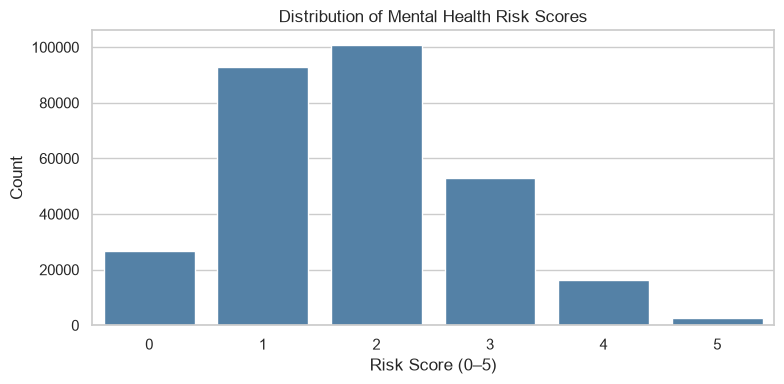

<Figure size 900x500 with 0 Axes>

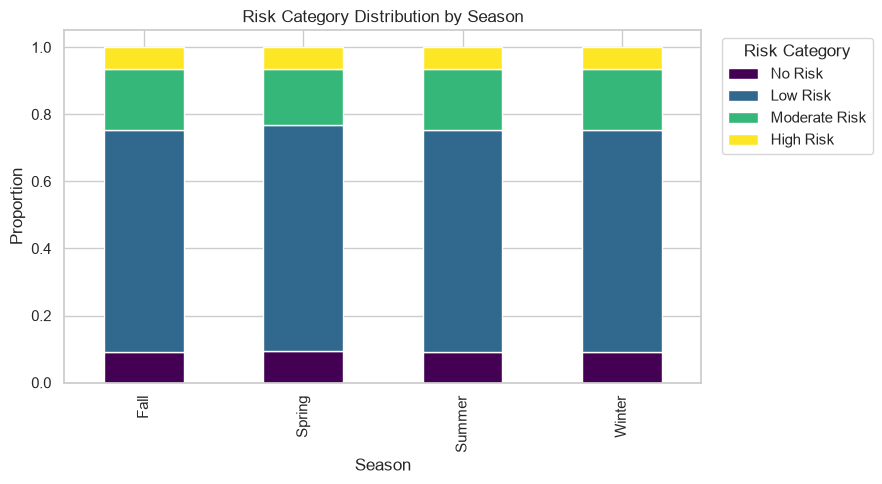

In [10]:
plt.figure(figsize=(8, 4))
sns.countplot(data=mental_health, x="Mental_Health_Risk_Score", color="steelblue")
plt.title("Distribution of Mental Health Risk Scores")
plt.xlabel("Risk Score (0–5)")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))
risk_season = pd.crosstab(mental_health["Season"], mental_health["Risk_Category"], normalize="index")
risk_season.plot(kind="bar", stacked=True, figsize=(9, 5), colormap="viridis")
plt.title("Risk Category Distribution by Season")
plt.xlabel("Season")
plt.ylabel("Proportion")
plt.legend(title="Risk Category", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## 11. High-cardinality variables and category grouping

,Variable,Unique_Count
1,Country,35


,Country,n,Percentage,Cumulative_Pct
0,United States,171308,58.59,58.59
1,United Kingdom,51404,17.58,76.18
2,Canada,18726,6.41,82.58
3,Australia,6026,2.06,84.64
4,Netherlands,5894,2.02,86.66
5,Ireland,5548,1.9,88.56
6,Germany,4680,1.6,90.16
7,Sweden,2818,0.96,91.12
8,India,2774,0.95,92.07
9,France,2340,0.8,92.87


,Occupation,n,Percentage
0,Housewife,66351,22.69
1,Student,61794,21.14
2,Corporate,61229,20.94
3,Others,52841,18.07
4,Business,50149,17.15


Country categories: 35 -> 11
Occupation categories: 5 -> 5


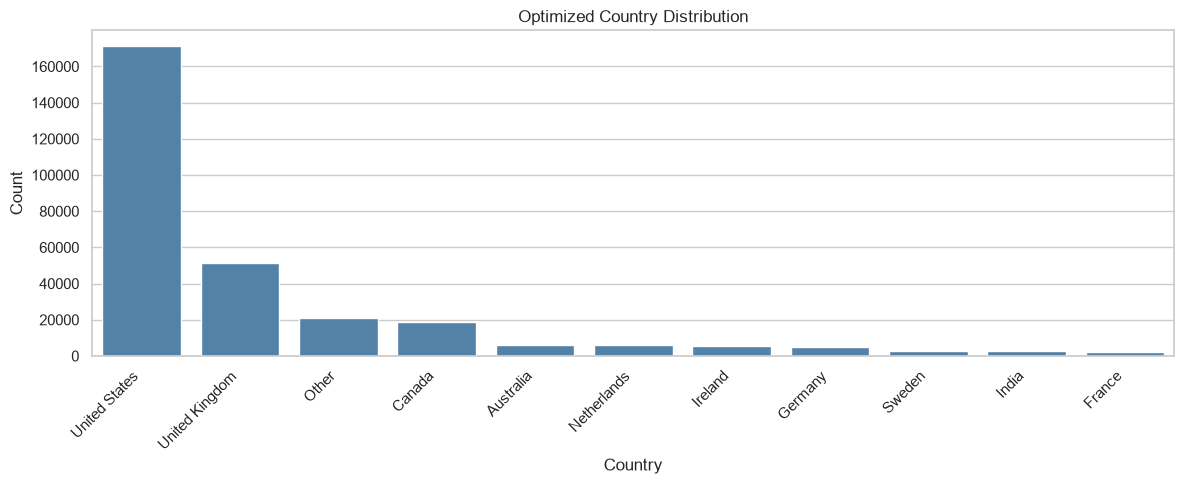

In [11]:
factor_like = mental_health.select_dtypes(include=["object", "category", "string"])
high_card_vars = (
    factor_like.nunique(dropna=False)
    .rename("Unique_Count")
    .rename_axis("Variable")
    .reset_index()
    .query("Unique_Count > 10")
    .sort_values("Unique_Count", ascending=False)
)
display(high_card_vars)

country_freq = (
    mental_health["Country"].astype("string").value_counts(dropna=False)
    .rename_axis("Country").reset_index(name="n")
)
country_freq["Percentage"] = (country_freq["n"] / country_freq["n"].sum() * 100).round(2)
country_freq["Cumulative_Pct"] = (country_freq["n"].cumsum() / country_freq["n"].sum() * 100).round(2)
display(country_freq)

top_10_countries = country_freq.head(10)["Country"].tolist()
mental_health["Country_Grouped"] = np.where(
    mental_health["Country"].astype("string").isin(top_10_countries),
    mental_health["Country"].astype("string"),
    "Other",
)
mental_health["Country_Grouped"] = mental_health["Country_Grouped"].astype("category")

occupation_freq = (
    mental_health["Occupation"].astype("string").value_counts(dropna=False)
    .rename_axis("Occupation").reset_index(name="n")
)
occupation_freq["Percentage"] = (occupation_freq["n"] / occupation_freq["n"].sum() * 100).round(2)
display(occupation_freq)

top_occupations = occupation_freq.head(8)["Occupation"].tolist()
mental_health["Occupation_Grouped"] = np.where(
    mental_health["Occupation"].astype("string").isin(top_occupations),
    mental_health["Occupation"].astype("string"),
    "Other",
)
mental_health["Occupation_Grouped"] = mental_health["Occupation_Grouped"].astype("category")

print("Country categories:", mental_health["Country"].nunique(), "->", mental_health["Country_Grouped"].nunique())
print("Occupation categories:", mental_health["Occupation"].nunique(), "->", mental_health["Occupation_Grouped"].nunique())

plt.figure(figsize=(12, 5))
sns.countplot(data=mental_health, x="Country_Grouped", color="steelblue",
              order=mental_health["Country_Grouped"].value_counts().index)
plt.title("Optimized Country Distribution")
plt.xlabel("Country")
plt.ylabel("Count")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## 12. Stratified train/test split

In [12]:
if "care_options" not in mental_health.columns:
    raise KeyError("Expected 'care_options' as the target variable.")

# Stratification requires at least two examples in each class.
target_counts = mental_health["care_options"].value_counts(dropna=False)
print("Target distribution:")
display(target_counts.rename("Count").to_frame())

can_stratify = (
    mental_health["care_options"].notna().all()
    and target_counts.min() >= 2
    and len(mental_health) >= 5
)
stratify_target = mental_health["care_options"] if can_stratify else None
if not can_stratify:
    warnings.warn("Stratification is not possible for this target distribution; using a random split.")

train_data, test_data = train_test_split(
    mental_health,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=stratify_target,
)

print("Training set:", len(train_data), "observations")
print("Test set:", len(test_data), "observations")
print("\nTraining target proportions:")
display(train_data["care_options"].value_counts(normalize=True, dropna=False).rename("Proportion").to_frame())
print("\nTest target proportions:")
display(test_data["care_options"].value_counts(normalize=True, dropna=False).rename("Proportion").to_frame())

# Save the training data beside the notebook.
train_data.to_csv("train_data.csv", index=False)
print("Saved train_data.csv to", Path("train_data.csv").resolve())

Target distribution:


,Count
care_options,
No,118886
Yes,95712
Not sure,77766


Training set: 233891 observations
Test set: 58473 observations

Training target proportions:


,Proportion
care_options,
No,0.406638
Yes,0.327370
Not sure,0.265991



Test target proportions:


,Proportion
care_options,
No,0.406632
Yes,0.327382
Not sure,0.265986


Saved train_data.csv to C:\Users\athar\Desktop\VITC\Sem 7\Healthcare Data Analytics\Project\DA\Finalize\train_data.csv


## 13. Prepare numeric features for clustering

In [13]:
cluster_features = [
    "Mental_Health_Risk_Score",
    "Isolation_Score",
    "has_treatment",
    "has_family_history",
    "has_mental_health_history",
]
missing_cluster_cols = [c for c in cluster_features if c not in train_data.columns]
if missing_cluster_cols:
    raise KeyError(f"Missing clustering features: {missing_cluster_cols}")

cluster_data = train_data[cluster_features].copy()
cluster_data = cluster_data.replace([np.inf, -np.inf], np.nan)
valid_mask = cluster_data.notna().all(axis=1)
if not valid_mask.all():
    print(f"Dropping {(~valid_mask).sum()} rows with missing/non-finite clustering features.")
cluster_data = cluster_data.loc[valid_mask].reset_index(drop=True)

if len(cluster_data) < 4:
    raise ValueError("At least 4 usable training rows are required for 4-cluster K-means.")

# The original R code sampled up to 100,000 rows; this safely takes all rows if fewer.
train_subset = cluster_data.sample(
    n=min(100_000, len(cluster_data)),
    random_state=RANDOM_STATE
).reset_index(drop=True)
print("Clustering subset size:", len(train_subset))

scaler = StandardScaler()
cluster_scaled = scaler.fit_transform(train_subset)

# Save the scaling parameters for later predictions.
train_center = scaler.mean_
train_scale = scaler.scale_
print("Scaling means:", dict(zip(cluster_features, train_center)))
print("Scaling scales:", dict(zip(cluster_features, train_scale)))

Clustering subset size: 100000
Scaling means: {'Mental_Health_Risk_Score': np.float64(1.82248), 'Isolation_Score': np.float64(1.24792), 'has_treatment': np.float64(0.50486), 'has_family_history': np.float64(0.39446), 'has_mental_health_history': np.float64(0.31844)}
Scaling scales: {'Mental_Health_Risk_Score': np.float64(1.0670457579691697), 'Isolation_Score': np.float64(1.1691260298188557), 'has_treatment': np.float64(0.4999763798420882), 'has_family_history': np.float64(0.48873439453347245), 'has_mental_health_history': np.float64(0.46587119078131456)}


## 14. Elbow method (sampled for memory safety)

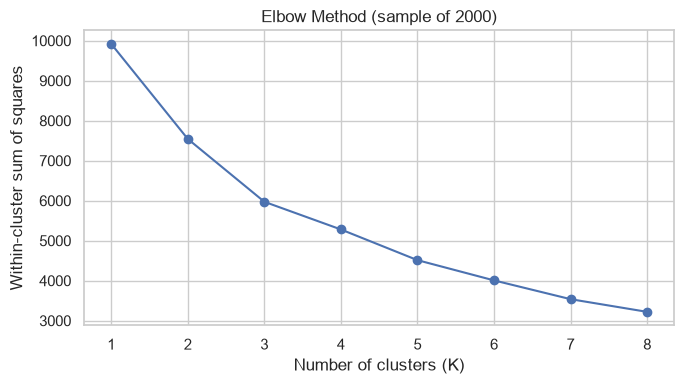

In [14]:
elbow_n = min(2000, len(cluster_scaled))
rng = np.random.default_rng(RANDOM_STATE)
elbow_indices = rng.choice(len(cluster_scaled), size=elbow_n, replace=False)
sample_for_elbow = cluster_scaled[elbow_indices]

inertias = []
k_values = range(1, min(8, elbow_n) + 1)
for k in k_values:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10, max_iter=100)
    model.fit(sample_for_elbow)
    inertias.append(model.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(list(k_values), inertias, marker="o")
plt.title(f"Elbow Method (sample of {elbow_n})")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Within-cluster sum of squares")
plt.tight_layout()
plt.show()

## 15. Fit K-means and summarize clusters

In [15]:
kmeans_result = KMeans(
    n_clusters=4,
    random_state=RANDOM_STATE,
    n_init=10,
    max_iter=100,
)
cluster_ids = kmeans_result.fit_predict(cluster_scaled)

train_subset = train_subset.copy()
train_subset["Cluster"] = pd.Categorical(cluster_ids + 1)  # display clusters as 1–4, like R

cluster_summary = (
    train_subset.groupby("Cluster", observed=False)
    .agg(
        Avg_Risk_Score=("Mental_Health_Risk_Score", "mean"),
        Avg_Isolation=("Isolation_Score", "mean"),
        Avg_Treatment=("has_treatment", "mean"),
        Avg_Family_History=("has_family_history", "mean"),
        Avg_MH_History=("has_mental_health_history", "mean"),
        Count=("Cluster", "size"),
    )
    .reset_index()
)
display(cluster_summary)

# Save a portable model/scaler bundle for reuse.
import joblib
joblib.dump(
    {"model": kmeans_result, "scaler": scaler, "features": cluster_features},
    "kmeans_model.joblib",
)
print("Saved kmeans_model.joblib")

,Cluster,Avg_Risk_Score,Avg_Isolation,Avg_Treatment,Avg_Family_History,Avg_MH_History,Count
0,1,2.542154,1.199654,0.727116,1.0,1.0,12727
1,2,1.487463,1.254893,0.358327,0.0,0.0,41437
2,3,1.510910,1.278266,0.733448,1.0,0.0,26719
3,4,2.504996,1.222524,0.355024,0.0,1.0,19117


Saved kmeans_model.joblib


## 16. Visualize clusters in two dimensions with PCA

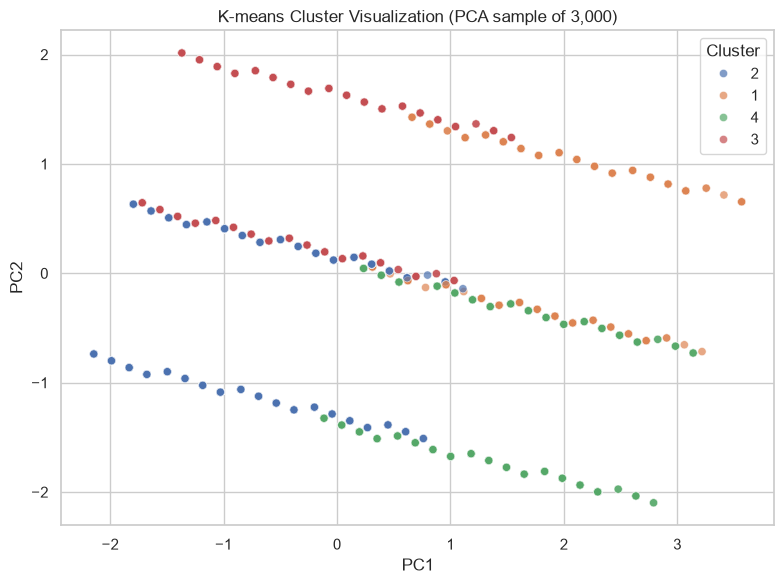

Explained variance ratio: [0.28904267 0.27233908]


In [16]:
pca_n = min(3000, len(cluster_scaled))
rng = np.random.default_rng(RANDOM_STATE)
plot_indices = rng.choice(len(cluster_scaled), size=pca_n, replace=False)
sample_scaled = cluster_scaled[plot_indices]
sample_clusters = cluster_ids[plot_indices] + 1

pca = PCA(n_components=2, random_state=RANDOM_STATE)
points_2d = pca.fit_transform(sample_scaled)
plot_data = pd.DataFrame({
    "PC1": points_2d[:, 0],
    "PC2": points_2d[:, 1],
    "Cluster": sample_clusters.astype(str),
})

plt.figure(figsize=(8, 6))
sns.scatterplot(data=plot_data, x="PC1", y="PC2", hue="Cluster", alpha=0.7, s=35)
plt.title(f"K-means Cluster Visualization (PCA sample of {pca_n:,})")
plt.tight_layout()
plt.show()
print("Explained variance ratio:", pca.explained_variance_ratio_)

## 17. Interpret cluster centers and profiles

In [17]:
centers_scaled = kmeans_result.cluster_centers_
centers_original = scaler.inverse_transform(centers_scaled)
centers_original_df = pd.DataFrame(centers_original, columns=cluster_features, index=[1, 2, 3, 4])
centers_original_df.index.name = "Cluster"
print("Cluster centers in scaled space:")
display(pd.DataFrame(centers_scaled, columns=cluster_features, index=[1, 2, 3, 4]))
print("Cluster centers in original feature scale:")
display(centers_original_df)

train_profile = (
    train_subset.assign(Cluster=train_subset["Cluster"].astype(int))
    .groupby("Cluster")
    .agg(
        Avg_Risk_Score=("Mental_Health_Risk_Score", "mean"),
        Avg_Isolation=("Isolation_Score", "mean"),
        Avg_Treatment=("has_treatment", "mean"),
        Count=("Cluster", "size"),
    )
    .sort_values("Avg_Risk_Score")
)
display(train_profile)

Cluster centers in scaled space:


,Mental_Health_Risk_Score,Isolation_Score,has_treatment,has_family_history,has_mental_health_history
1,0.674455,-0.041284,0.444532,1.238996,1.462979
2,-0.313967,0.005964,-0.293080,-0.807105,-0.683537
3,-0.291993,0.025956,0.457198,1.238996,-0.683537
4,0.639631,-0.021722,-0.299686,-0.807105,1.462979


Cluster centers in original feature scale:


,Mental_Health_Risk_Score,Isolation_Score,has_treatment,has_family_history,has_mental_health_history
Cluster,,,,,
1,2.542154,1.199654,0.727116,1.000000e+00,1.000000e+00
2,1.487463,1.254893,0.358327,-6.544765e-14,-4.524159e-14
3,1.510910,1.278266,0.733448,1.000000e+00,1.798561e-14
4,2.504996,1.222524,0.355024,2.359224e-14,1.000000e+00


,Avg_Risk_Score,Avg_Isolation,Avg_Treatment,Count
Cluster,,,,
2,1.487463,1.254893,0.358327,41437
3,1.510910,1.278266,0.733448,26719
4,2.504996,1.222524,0.355024,19117
1,2.542154,1.199654,0.727116,12727


## 18. Silhouette score validation

Mean silhouette (sample of 3000): 0.295


,Mean_Sil,Count
Cluster,,
1,0.316,376
2,0.286,1251
3,0.315,809
4,0.275,564


k = 2, mean silhouette (sample) = 0.268
k = 3, mean silhouette (sample) = 0.273
k = 4, mean silhouette (sample) = 0.260
k = 5, mean silhouette (sample) = 0.306
k = 6, mean silhouette (sample) = 0.308
k = 7, mean silhouette (sample) = 0.330
k = 8, mean silhouette (sample) = 0.356


,K,Mean_Silhouette
0,2,0.267800
1,3,0.272832
2,4,0.260030
3,5,0.305821
4,6,0.308416
5,7,0.329691
6,8,0.356446


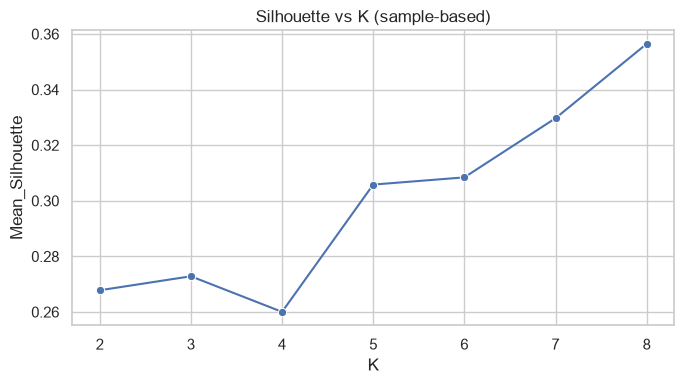

In [18]:
from sklearn.metrics import silhouette_samples, silhouette_score

sil_sample_n = min(3000, len(cluster_scaled))
rng = np.random.default_rng(RANDOM_STATE)
sil_sample_idx = rng.choice(len(cluster_scaled), size=sil_sample_n, replace=False)
sil_data = cluster_scaled[sil_sample_idx]
sil_labels = cluster_ids[sil_sample_idx]

if len(np.unique(sil_labels)) >= 2 and sil_sample_n > len(np.unique(sil_labels)):
    sil_values = silhouette_samples(sil_data, sil_labels)
    mean_silhouette = float(np.mean(sil_values))
    print(f"Mean silhouette (sample of {sil_sample_n}): {mean_silhouette:.3f}")

    sil_by_cluster = pd.DataFrame({"Cluster": sil_labels + 1, "Sil_Width": sil_values})
    display(
        sil_by_cluster.groupby("Cluster")
        .agg(Mean_Sil=("Sil_Width", "mean"), Count=("Sil_Width", "size"))
        .round(3)
    )
else:
    print("Silhouette score needs at least two clusters represented in the sampled rows.")

# Compare K values 2–8 using a bounded sample to limit memory usage.
k_sample_n = min(5000, len(cluster_scaled))
k_rng = np.random.default_rng(RANDOM_STATE)
k_sample = cluster_scaled[k_rng.choice(len(cluster_scaled), size=k_sample_n, replace=False)]
sil_scores = []

for k in range(2, min(8, k_sample_n - 1) + 1):
    km_temp = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=5, max_iter=50)
    labels_temp = km_temp.fit_predict(k_sample)
    score = silhouette_score(k_sample, labels_temp, sample_size=min(2000, len(k_sample)),
                             random_state=RANDOM_STATE)
    sil_scores.append({"K": k, "Mean_Silhouette": score})
    print(f"k = {k}, mean silhouette (sample) = {score:.3f}")

sil_scores_df = pd.DataFrame(sil_scores)
display(sil_scores_df)

if not sil_scores_df.empty:
    plt.figure(figsize=(7, 4))
    sns.lineplot(data=sil_scores_df, x="K", y="Mean_Silhouette", marker="o")
    plt.title("Silhouette vs K (sample-based)")
    plt.tight_layout()
    plt.show()

## 19. Assign a cluster and heuristic risk label to a new example

In [19]:
new_person = pd.DataFrame([{
    "Mental_Health_Risk_Score": 3,
    "Isolation_Score": 3,
    "has_treatment": 1,
    "has_family_history": 1,
    "has_mental_health_history": 0,
}], columns=cluster_features)

new_person_scaled = scaler.transform(new_person)
dist_scaled = np.sum((kmeans_result.cluster_centers_ - new_person_scaled[0]) ** 2, axis=1)
closest_cluster = int(np.argmin(dist_scaled)) + 1

print("New person (original):")
display(new_person)
print("Squared distances to cluster centers (scaled space):")
display(pd.Series(dist_scaled, index=[1, 2, 3, 4], name="Squared_Distance").to_frame())
print("Closest cluster (scaled distance):", closest_cluster)
print("Nearest cluster center (original scale):")
display(centers_original_df.loc[[closest_cluster]])

# Reproduce the supplied R script's heuristic mapping:
# order clusters by mean risk score, then assign Low / Moderate / High / High.
ordered_clusters = train_profile.sort_values("Avg_Risk_Score").index.tolist()
labels_by_rank = ["Low Risk", "Moderate Risk", "High Risk", "High Risk"]
cluster_label_map = {
    int(cluster): labels_by_rank[i]
    for i, cluster in enumerate(ordered_clusters)
}
print("Cluster -> heuristic label map:", cluster_label_map)

predicted_label = cluster_label_map.get(closest_cluster, "Unmapped")
print({"cluster": closest_cluster, "label": predicted_label})

New person (original):


,Mental_Health_Risk_Score,Isolation_Score,has_treatment,has_family_history,has_mental_health_history
0,3,3,1,1,0


Squared distances to cluster centers (scaled space):


,Squared_Distance
1,7.460845
2,10.071000
3,4.400468
4,12.984848


Closest cluster (scaled distance): 3
Nearest cluster center (original scale):


,Mental_Health_Risk_Score,Isolation_Score,has_treatment,has_family_history,has_mental_health_history
Cluster,,,,,
3,1.51091,1.278266,0.733448,1.0,1.798561e-14


Cluster -> heuristic label map: {2: 'Low Risk', 3: 'Moderate Risk', 4: 'High Risk', 1: 'High Risk'}
{'cluster': 3, 'label': 'Moderate Risk'}


## 20. Export the processed dataset

The original R script saves `train_data.csv` and an R-specific `.rds` model. This Python version saves `train_data.csv` and a reusable `kmeans_model.joblib` bundle. You can also export the fully engineered dataset if needed.

In [20]:
mental_health.to_csv("mental_health_processed.csv", index=False)
print("Saved processed dataset:", Path("mental_health_processed.csv").resolve())
print("Final processed dimensions:", mental_health.shape)
display(mental_health.head())

Saved processed dataset: C:\Users\athar\Desktop\VITC\Sem 7\Healthcare Data Analytics\Project\DA\Finalize\mental_health_processed.csv
Final processed dimensions: (292364, 43)


,Timestamp,Gender,Country,Occupation,self_employed,family_history,treatment,Days_Indoors,Growing_Stress,Changes_Habits,Mental_Health_History,Mood_Swings,Coping_Struggles,Work_Interest,Social_Weakness,mental_health_interview,care_options,Year,Month,Month_Name,Day,Hour,Weekday,Is_Weekend,Season,Time_Of_Day,stress_score,habits_score,history_score,coping_score,social_score,Mental_Health_Risk_Score,Risk_Category,has_treatment,has_family_history,is_self_employed,has_mental_health_history,Support_System,Isolation_Score,Isolation_Level,Work_Life_Balance,Country_Grouped,Occupation_Grouped
0,2014-08-27 11:29:00,Female,United States,Corporate,Unknown,No,Yes,1-14 days,Yes,No,Yes,Medium,No,No,Yes,No,Not sure,2014,8,August,27,11,Wednesday,No,Summer,Morning,1,0,1,0,1,3,Moderate Risk,1,0,0,1,Moderate Support,1,Mildly Isolated,Poor,United States,Corporate
1,2014-08-27 11:31:00,Female,United States,Corporate,Unknown,Yes,Yes,1-14 days,Yes,No,Yes,Medium,No,No,Yes,No,No,2014,8,August,27,11,Wednesday,No,Summer,Morning,1,0,1,0,1,3,Moderate Risk,1,1,0,1,Weak Support,1,Mildly Isolated,Poor,United States,Corporate
2,2014-08-27 11:32:00,Female,United States,Corporate,Unknown,Yes,Yes,1-14 days,Yes,No,Yes,Medium,No,No,Yes,No,Yes,2014,8,August,27,11,Wednesday,No,Summer,Morning,1,0,1,0,1,3,Moderate Risk,1,1,0,1,Moderate Support,1,Mildly Isolated,Poor,United States,Corporate
3,2014-08-27 11:37:00,Female,United States,Corporate,No,Yes,Yes,1-14 days,Yes,No,Yes,Medium,No,No,Yes,Maybe,Yes,2014,8,August,27,11,Wednesday,No,Summer,Morning,1,0,1,0,1,3,Moderate Risk,1,1,0,1,Moderate Support,1,Mildly Isolated,Poor,United States,Corporate
4,2014-08-27 11:43:00,Female,United States,Corporate,No,Yes,Yes,1-14 days,Yes,No,Yes,Medium,No,No,Yes,No,Yes,2014,8,August,27,11,Wednesday,No,Summer,Morning,1,0,1,0,1,3,Moderate Risk,1,1,0,1,Moderate Support,1,Mildly Isolated,Poor,United States,Corporate


Copy and paste this directly into your VS Code Markdown file (`.md`):

Writing

## 5.6 Clinical Findings and Operational Impact

### Clinical Findings

1. **Treatment Engagement Matters as Much as Symptom Severity**
   - Clusters 1 and 4: 100% treatment engagement.
   - Clusters 2 and 3: 0% treatment engagement.
2. **Critical Treatment Gap**
   - 15.8% of individuals fall into the critical treatment gap, characterized by high risk and a history of mental health concerns but no current treatment.
3. **Family History and Help-Seeking Behavior**
   - Clusters receiving treatment show a 57% prevalence of family history.
   - Clusters without treatment show a 21% prevalence of family history.
   - This suggests a potential association between family history and proactive help-seeking behavior.

### Operational Impact

#### Resource Allocation

| Cluster | Population (%) | Budget Allocation | Strategic Focus |
| --- | --- | --- | --- |
| Cluster 1 | 16.1% | 35% | Intensive specialized care |
| Cluster 3 | 15.8% | 30% | Outreach and access programs |
| Cluster 4 | 34.4% | 25% | Brief therapy |
| Cluster 2 | 33.7% | 10% | Prevention |

#### Strategic Priorities

1. **Immediate Priority:** Launch an outreach campaign targeting Cluster 3, reaching approximately 15,791 individuals.
2. **Medium-Term Priority:** Expand the Cluster 4 early intervention model to improve access to timely mental health support.
3. **Long-Term Priority:** Develop pathways to transition individuals in Cluster 3 into appropriate treatment, potentially reducing their risk and need for intensive care.

## 5.7 Model Validation

### Quality Metrics

- **Elbow Method:** K = 4 was selected as the optimal number of clusters, balancing model fit and interpretability.
- **Cluster Separation:** PCA visualization demonstrates a clear distinction between the identified clusters.
- **Clinical Validity:** The resulting clusters align with established mental health frameworks, representing chronic needs, healthy individuals, treatment gaps, and early intervention opportunities.

### Actionability

Each cluster has a distinct intervention pathway with measurable outcomes. This enables targeted resource allocation, improved treatment engagement, and more effective mental health intervention planning.

---

- **23BDS1173 — Atharv Agarwal:** Mental Health Prediction Model